In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/kaggle/input/datasets/lakshmideepikapeyala/covid-19/WHO COVID-19 cases.csv')
print(df.shape)
df.head()

(58560, 9)


,Date_reported,Country_code,Country,Continent,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
0,1/5/2020,AF,Afghanistan,Asia,EMRO,0,0,0,0
1,1/12/2020,AF,Afghanistan,Asia,EMRO,0,0,0,0
2,1/19/2020,AF,Afghanistan,Asia,EMRO,0,0,0,0
3,1/26/2020,AF,Afghanistan,Asia,EMRO,0,0,0,0
4,2/2/2020,AF,Afghanistan,Asia,EMRO,0,0,0,0


In [2]:
df['Date_reported'] = pd.to_datetime(df['Date_reported'])
df.head()

,Date_reported,Country_code,Country,Continent,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
0,2020-01-05,AF,Afghanistan,Asia,EMRO,0,0,0,0
1,2020-01-12,AF,Afghanistan,Asia,EMRO,0,0,0,0
2,2020-01-19,AF,Afghanistan,Asia,EMRO,0,0,0,0
3,2020-01-26,AF,Afghanistan,Asia,EMRO,0,0,0,0
4,2020-02-02,AF,Afghanistan,Asia,EMRO,0,0,0,0


In [6]:
df.isnull().sum()

Date_reported           0
Country_code          244
Country                 0
Continent               0
WHO_region           4392
New_cases               0
Cumulative_cases        0
New_deaths              0
Cumulative_deaths       0
dtype: int64

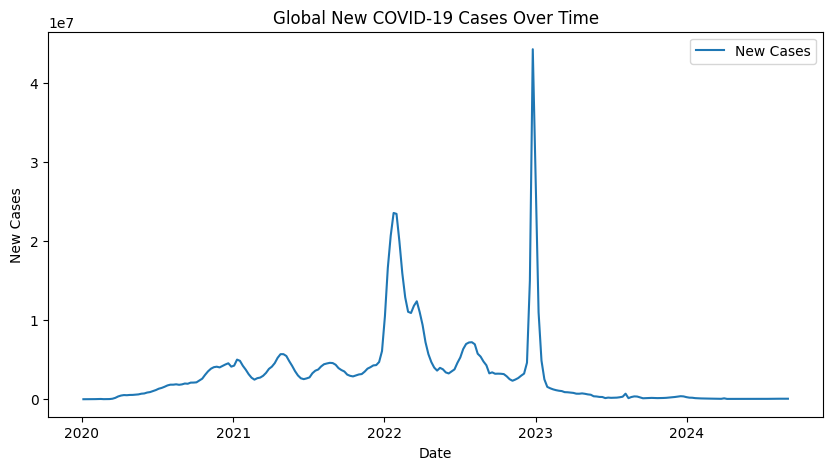

In [7]:
global_trend = df.groupby('Date_reported')[['New_cases','New_deaths']].sum().reset_index()

plt.figure(figsize=(10,5))
plt.plot(global_trend['Date_reported'], global_trend['New_cases'], label='New Cases')
plt.title('Global New COVID-19 Cases Over Time')
plt.xlabel('Date')
plt.ylabel('New Cases')
plt.legend()
plt.show()

                                               Country  Cumulative_cases  \
229                           United States of America         103436829   
42                                               China          99379039   
96                                               India          45042802   
72                                              France          38997490   
78                                             Germany          38437756   
28                                              Brazil          37511921   
175                                  Republic of Korea          34571873   
111                                              Japan          33803572   
109                                              Italy          26826486   
226  United Kingdom of Great Britain and Northern I...          24983630   

     Cumulative_deaths  
229            1197213  
42              122326  
96              533636  
72              168091  
78              174979  
28           

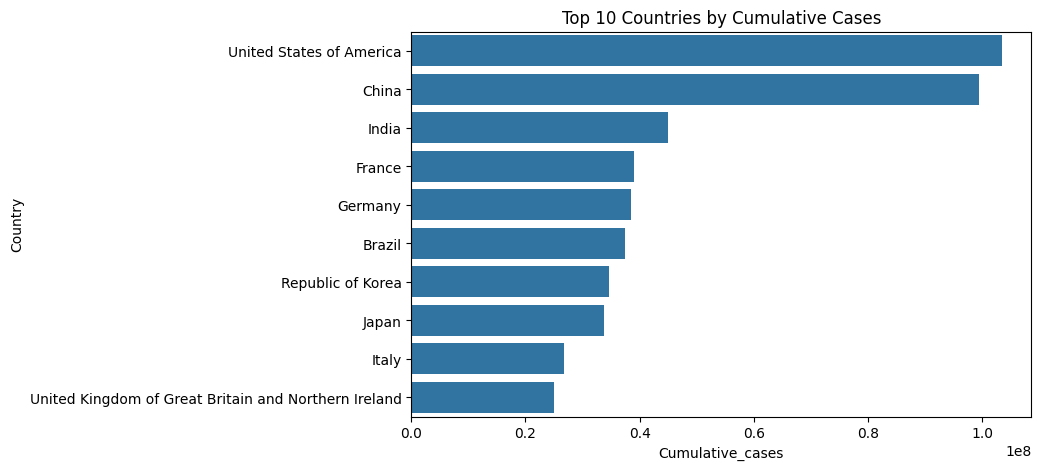

In [8]:
latest = df.sort_values('Date_reported').groupby('Country').last().reset_index()
top10_cases = latest.sort_values('Cumulative_cases', ascending=False).head(10)
print(top10_cases[['Country','Cumulative_cases','Cumulative_deaths']])

plt.figure(figsize=(8,5))
sns.barplot(x='Cumulative_cases', y='Country', data=top10_cases)
plt.title('Top 10 Countries by Cumulative Cases')
plt.show()

WHO_region
EURO     279740542
WPRO     208565260
AMRO     192742456
SEARO     61316790
EMRO      23417911
AFRO       9043942
OTHER          764
Name: New_cases, dtype: int64


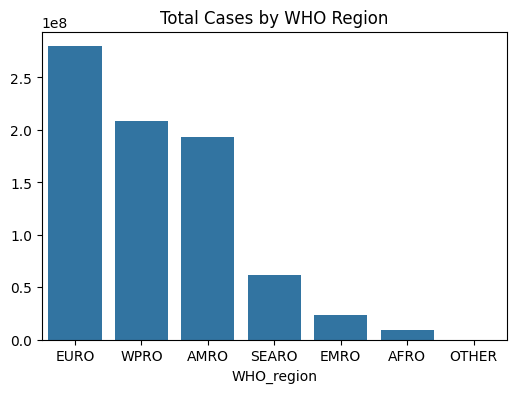

In [9]:
region_cases = df.groupby('WHO_region')['New_cases'].sum().sort_values(ascending=False)
print(region_cases)

plt.figure(figsize=(6,4))
sns.barplot(x=region_cases.index, y=region_cases.values)
plt.title('Total Cases by WHO Region')
plt.show()

In [10]:
latest['CFR'] = (latest['Cumulative_deaths'] / latest['Cumulative_cases'].replace(0, np.nan)) * 100
top_cfr = latest.sort_values('Cumulative_cases', ascending=False).head(15)[['Country','CFR']]
print(top_cfr)

                                               Country       CFR
229                           United States of America  1.157434
42                                               China  0.123090
96                                               India  1.184731
72                                              France  0.431030
78                                             Germany  0.455227
28                                              Brazil  1.871714
175                                  Republic of Korea  0.103940
111                                              Japan  0.220965
109                                              Italy  0.736369
226  United Kingdom of Great Britain and Northern I...  0.929056
178                                 Russian Federation  1.657391
222                                            Türkiye  0.596417
204                                              Spain  0.871595
11                                           Australia  0.212762
234                      

In [11]:
df['YearMonth'] = df['Date_reported'].dt.to_period('M')
monthly = df.groupby('YearMonth')['New_cases'].sum()
print(monthly.tail())

YearMonth
2024-05    136178
2024-06    190797
2024-07    206458
2024-08    248049
2024-09     63361
Freq: M, Name: New_cases, dtype: int64


In [13]:
df.to_csv('who_covid_cleaned.csv', index=False)
print("Cleaned file saved: who_covid_cleaned.csv")

Cleaned file saved: who_covid_cleaned.csv
